In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
PROJ = Path.home() / "Documents/v2x-ids"
FIG = PROJ / "results/figures"
msgs = pd.read_parquet(PROJ / "data/processed/msgs_run79200.parquet")
print(msgs.shape)

(157531, 25)


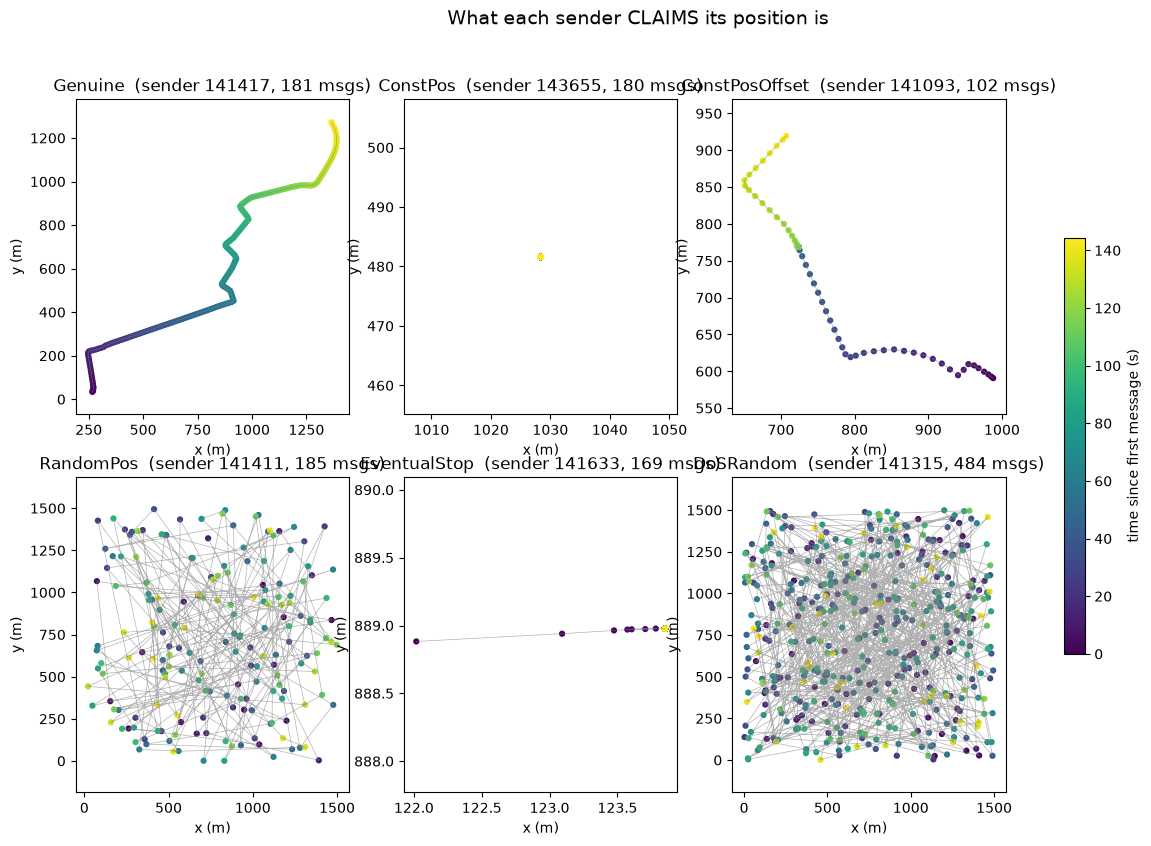

In [3]:
unique = msgs.drop_duplicates("message_id")
show = ["Genuine", "ConstPos", "ConstPosOffset", "RandomPos", "EventualStop", "DoSRandom"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, name in zip(axes.flat, show):
    sub = unique[unique["attack_name"] == name]
    sender = sub["sender"].value_counts().idxmax()
    path = sub[sub["sender"] == sender].sort_values("send_time")
    sc = ax.scatter(path["pos_x"], path["pos_y"],
                    c=path["send_time"] - path["send_time"].min(), cmap="viridis", s=12)
    ax.plot(path["pos_x"], path["pos_y"], lw=0.5, color="grey", alpha=0.6)
    ax.set_title(f"{name}  (sender {sender}, {len(path)} msgs)")
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
    ax.set_aspect("equal", adjustable="datalim")
fig.colorbar(sc, ax=axes, label="time since first message (s)", shrink=0.6)
fig.suptitle("What each sender CLAIMS its position is", fontsize=14)
fig.savefig(FIG / "fig_claimed_paths.png", dpi=150, bbox_inches="tight")
plt.show()

attack_name
GridSybil             0.167
DoSDisruptive         0.250
DoSRandom             0.250
DoS                   0.500
DoSDisruptiveSybil    0.500
DoSRandomSybil        0.500
Disruptive            1.000
ConstPos              1.000
ConstPosOffset        1.000
RandomPos             1.000
ConstSpeed            1.000
DataReplaySybil       1.000
RandomSpeed           1.000
DelayedMessages       1.000
Genuine               1.000
EventualStop          1.000
RandomPosOffset       1.000
ConstSpeedOffset      1.000
DataReplay            1.000
RandomSpeedOffset     1.000
Name: gap, dtype: float64


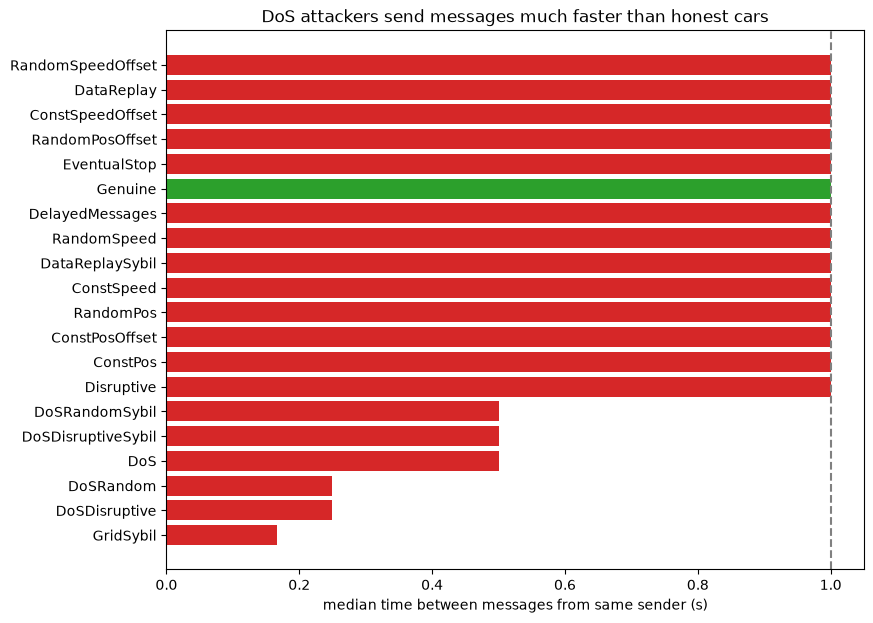

In [4]:
msgs = msgs.sort_values(["receiver", "sender", "rcv_time"])
msgs["gap"] = msgs.groupby(["receiver", "sender"])["rcv_time"].diff()
summary = msgs.dropna(subset=["gap"]).groupby("attack_name")["gap"].median().sort_values()
print(summary.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
colors = ["tab:green" if n == "Genuine" else "tab:red" for n in summary.index]
ax.barh(summary.index, summary.values, color=colors)
ax.axvline(1.0, ls="--", color="grey")
ax.set_xlabel("median time between messages from same sender (s)")
ax.set_title("DoS attackers send messages much faster than honest cars")
fig.savefig(FIG / "fig_message_gaps.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
import sys
from pathlib import Path
import pandas as pd
sys.path.append(str(Path.cwd().parent / "src"))
from features import add_features, FEATURES

PROJ = Path.home() / "Documents/v2x-ids"
msgs = pd.read_parquet(PROJ / "data/processed/msgs_run79200.parquet")
ego = pd.read_parquet(PROJ / "data/processed/ego_run79200.parquet")

feat = add_features(msgs, ego)
print(feat.shape, "|", len(FEATURES), "features")

(157531, 42) | 15 features


In [7]:
cols = ["speed", "dist_to_receiver", "dt", "jump", "speed_mismatch",
        "pos_pred_error", "heading_vs_motion_deg", "msgs_last_1s", "pseudos_nearby_1s"]
pd.set_option("display.width", 200)
feat.groupby("attack_name")[cols].median().round(2)

,speed,dist_to_receiver,dt,jump,speed_mismatch,pos_pred_error,heading_vs_motion_deg,msgs_last_1s,pseudos_nearby_1s
attack_name,,,,,,,,,
ConstPos,12.28,659.85,1.00,0.00,12.18,12.41,NaN,1.0,1.0
ConstPosOffset,11.53,133.37,1.00,11.69,0.09,0.37,0.64,1.0,1.0
ConstSpeed,36.14,79.11,1.00,13.42,27.37,33.75,53.35,1.0,1.0
ConstSpeedOffset,10.67,70.34,1.00,12.61,6.48,12.66,47.58,1.0,1.0
DataReplay,11.84,104.23,1.00,46.04,23.56,43.05,29.85,1.0,1.0
DataReplaySybil,12.08,116.56,1.00,10.59,0.10,0.39,0.78,1.0,2.0
DelayedMessages,0.00,700.79,1.00,0.00,0.00,0.00,0.54,1.0,1.0
Disruptive,11.63,218.50,1.00,212.55,197.55,212.39,89.76,1.0,1.0
DoS,11.96,115.26,0.50,0.00,11.97,3.41,0.55,3.0,1.0


In [8]:
feat.to_parquet(PROJ / "data/processed/features_run79200.parquet")
print("Saved!")

Saved!


Data quality check

Cell 1: Load

In [ ]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
sys.path.append(str(Path.cwd().parent / "src"))
from features import FEATURES

PROJ = Path.home() / "Documents/v2x-ids"
df = pd.read_parquet(PROJ / "data/processed/features_run79200.parquet")
print(df.shape)

Cell 2: Quality checks

In [10]:
print("Duplicates:", df.duplicated(["receiver", "message_id"]).sum())
print("Infinite values:", np.isinf(df[FEATURES]).sum().sum())
print("Negative time gaps:", (df["dt"] < 0).sum())
print("\nMissing % per feature:")
print((df[FEATURES].isna().mean() * 100).round(1))

Duplicates: 0
Infinite values: 0
Negative time gaps: 0

Missing % per feature:
speed                       0.0
accel                       0.0
heading_vs_velocity_deg     2.0
dist_to_receiver            0.0
is_first                    0.0
dt                         10.8
jump                       10.8
implied_speed              10.8
speed_mismatch             10.8
pos_pred_error             10.8
speed_change_rate          10.8
accel_mismatch             10.8
heading_vs_motion_deg      28.0
msgs_last_1s                0.0
pseudos_nearby_1s           0.0
dtype: float64


keep missing values and outliers

In [11]:
print(df.groupby("attack_name")["is_first"].mean().sort_values(ascending=False).head(3).round(2))
df.groupby("is_attack")["implied_speed"].describe(percentiles=[.5, .99]).round(1)

attack_name
DoSDisruptiveSybil    0.89
DoSRandomSybil        0.81
DataReplaySybil       0.47
Name: is_first, dtype: float64


,count,mean,std,min,50%,99%,max
is_attack,,,,,,,
0,87909.0,9.9,5.3,0.0,12.3,16.4,18.5
1,52635.0,511.4,1098.6,0.0,14.2,5206.0,9277.9
